<a href="https://colab.research.google.com/github/srushtivelhal2006/Brain_tumor_Classification/blob/main/brain_tunmor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os

print("Files available:")
for item in os.listdir('.'):
    print(f"  {item}")

Files available:
  .config
  sample_data


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!ls "/content/drive/MyDrive/Brain Tumor"

 brainTumorDataPublic_15332298.zip   brainTumorDataPublic_7671532.zip
 brainTumorDataPublic_1766.zip	    'kaggle dataset.zip'
 brainTumorDataPublic_22993064.zip


In [ ]:
import os

os.makedirs('/content/data', exist_ok=True)

!unzip -q "/content/drive/MyDrive/BrainTumor/brainTumorDataPublic_1766.zip" -d "/content/data/brainTumorDataPublic_1766"
!unzip -q "/content/drive/MyDrive/BrainTumor/brainTumorDataPublic_7671532.zip" -d "/content/data/brainTumorDataPublic_7671532"
!unzip -q "/content/drive/MyDrive/BrainTumor/brainTumorDataPublic_15332298.zip" -d "/content/data/brainTumorDataPublic_15332298"
!unzip -q "/content/drive/MyDrive/BrainTumor/brainTumorDataPublic_22993064.zip" -d "/content/data/brainTumorDataPublic_22993064"
!unzip -q "/content/drive/MyDrive/BrainTumor/kaggle dataset.zip" -d "/content/data/kaggle_dataset"

print("All unzipped!")

All unzipped!


In [ ]:
folders = [
    "/content/data/brainTumorDataPublic_1766",
    "/content/data/brainTumorDataPublic_7671532",
    "/content/data/brainTumorDataPublic_15332298",
    "/content/data/brainTumorDataPublic_22993064",
    "/content/data/kaggle_dataset"
]

for folder in folders:
    if os.path.exists(folder):
        print(f"Found: {folder.split('/')[-1]} - {len(os.listdir(folder))} files")
    else:
        print(f"MISSING: {folder}")

Found: brainTumorDataPublic_1766 - 766 files
Found: brainTumorDataPublic_7671532 - 766 files
Found: brainTumorDataPublic_15332298 - 766 files
Found: brainTumorDataPublic_22993064 - 766 files
Found: kaggle_dataset - 2 files


In [ ]:
import os
import h5py
import numpy as np
import cv2
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import tensorflow as tf
import warnings
warnings.filterwarnings('ignore')

print("All imported!")
print(f"TensorFlow: {tf.__version__}")
print(f"GPU available: {tf.config.list_physical_devices('GPU')}")

All imported!
TensorFlow: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
data_folders = [
    "/content/data/brainTumorDataPublic_1766",
    "/content/data/brainTumorDataPublic_7671532",
    "/content/data/brainTumorDataPublic_15332298",
    "/content/data/brainTumorDataPublic_22993064"
]

IMG_SIZE = 128
images = []
labels = []
corrupt = 0

for folder in data_folders:
    files = sorted(os.listdir(folder))
    print(f"Processing {folder.split('/')[-1]} - {len(files)} files")
    for file in files:
        if not file.endswith('.mat'):
            continue
        filepath = os.path.join(folder, file)
        try:
            with h5py.File(filepath, 'r') as f:
                image = f['cjdata']['image'][()]
                label = int(f['cjdata']['label'][0][0])
                img = image.astype(np.float64)
                img_min, img_max = img.min(), img.max()
                if img_max - img_min > 0:
                    img = (255 / (img_max - img_min)) * (img - img_min)
                img = img.astype(np.uint8)
                img_resized = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
                img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_GRAY2RGB)
                images.append(img_rgb)
                labels.append(label - 1)
        except Exception as e:
            corrupt += 1

print(f"MAT loaded! Images: {len(images)}, Corrupted: {corrupt}")

Processing brainTumorDataPublic_1766 - 766 files
Processing brainTumorDataPublic_7671532 - 766 files
Processing brainTumorDataPublic_15332298 - 766 files
Processing brainTumorDataPublic_22993064 - 766 files
MAT loaded! Images: 3064, Corrupted: 0


In [ ]:
kaggle_label_map = {
    'meningioma': 0,
    'glioma': 1,
    'pituitary': 2,
    'notumor': 3
}

kaggle_splits = [
    "/content/data/kaggle_dataset/Training",
    "/content/data/kaggle_dataset/Testing"
]

kaggle_count = 0

for split in kaggle_splits:
    if not os.path.exists(split):
        print(f"Path not found: {split}")
        continue
    for class_name in os.listdir(split):
        class_path = os.path.join(split, class_name)
        if not os.path.isdir(class_path):
            continue
        label = kaggle_label_map.get(class_name.lower())
        if label is None:
            continue
        for file in os.listdir(class_path):
            if not file.lower().endswith(('.jpg','.jpeg','.png')):
                continue
            try:
                img = cv2.imread(os.path.join(class_path, file))
                img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                images.append(img)
                labels.append(label)
                kaggle_count += 1
            except:
                corrupt += 1

images = np.array(images)
labels = np.array(labels)

print(f"Kaggle loaded! Added: {kaggle_count} images")
print(f"Total images: {len(images)}")
print(f"Labels: {np.unique(labels)}")

Kaggle loaded! Added: 7200 images
Total images: 10264
Labels: [0 1 2 3]


Class Distribution:
  Meningioma: 2508 images
  Glioma: 3226 images
  Pituitary: 2730 images
  No Tumor: 1800 images
  Total: 10264


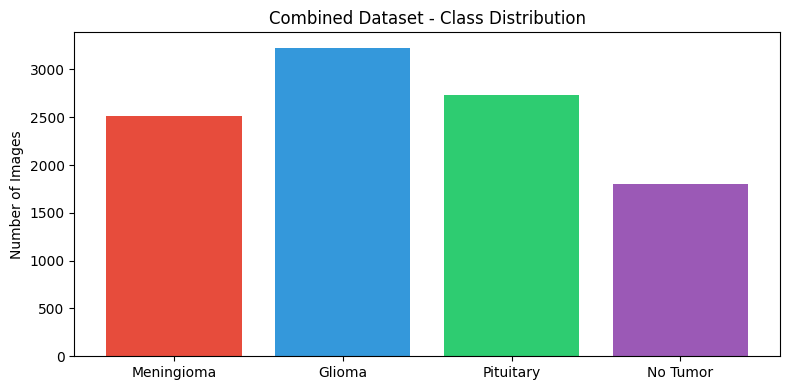

In [ ]:
label_names = {0:'Meningioma', 1:'Glioma', 2:'Pituitary', 3:'No Tumor'}
counts = {label_names[i]: np.sum(labels == i) for i in range(4)}

print("Class Distribution:")
for cls, count in counts.items():
    print(f"  {cls}: {count} images")
print(f"  Total: {len(images)}")

plt.figure(figsize=(8, 4))
plt.bar(counts.keys(), counts.values(),
        color=['#e74c3c','#3498db','#2ecc71','#9b59b6'])
plt.title('Combined Dataset - Class Distribution')
plt.ylabel('Number of Images')
plt.tight_layout()
plt.show()

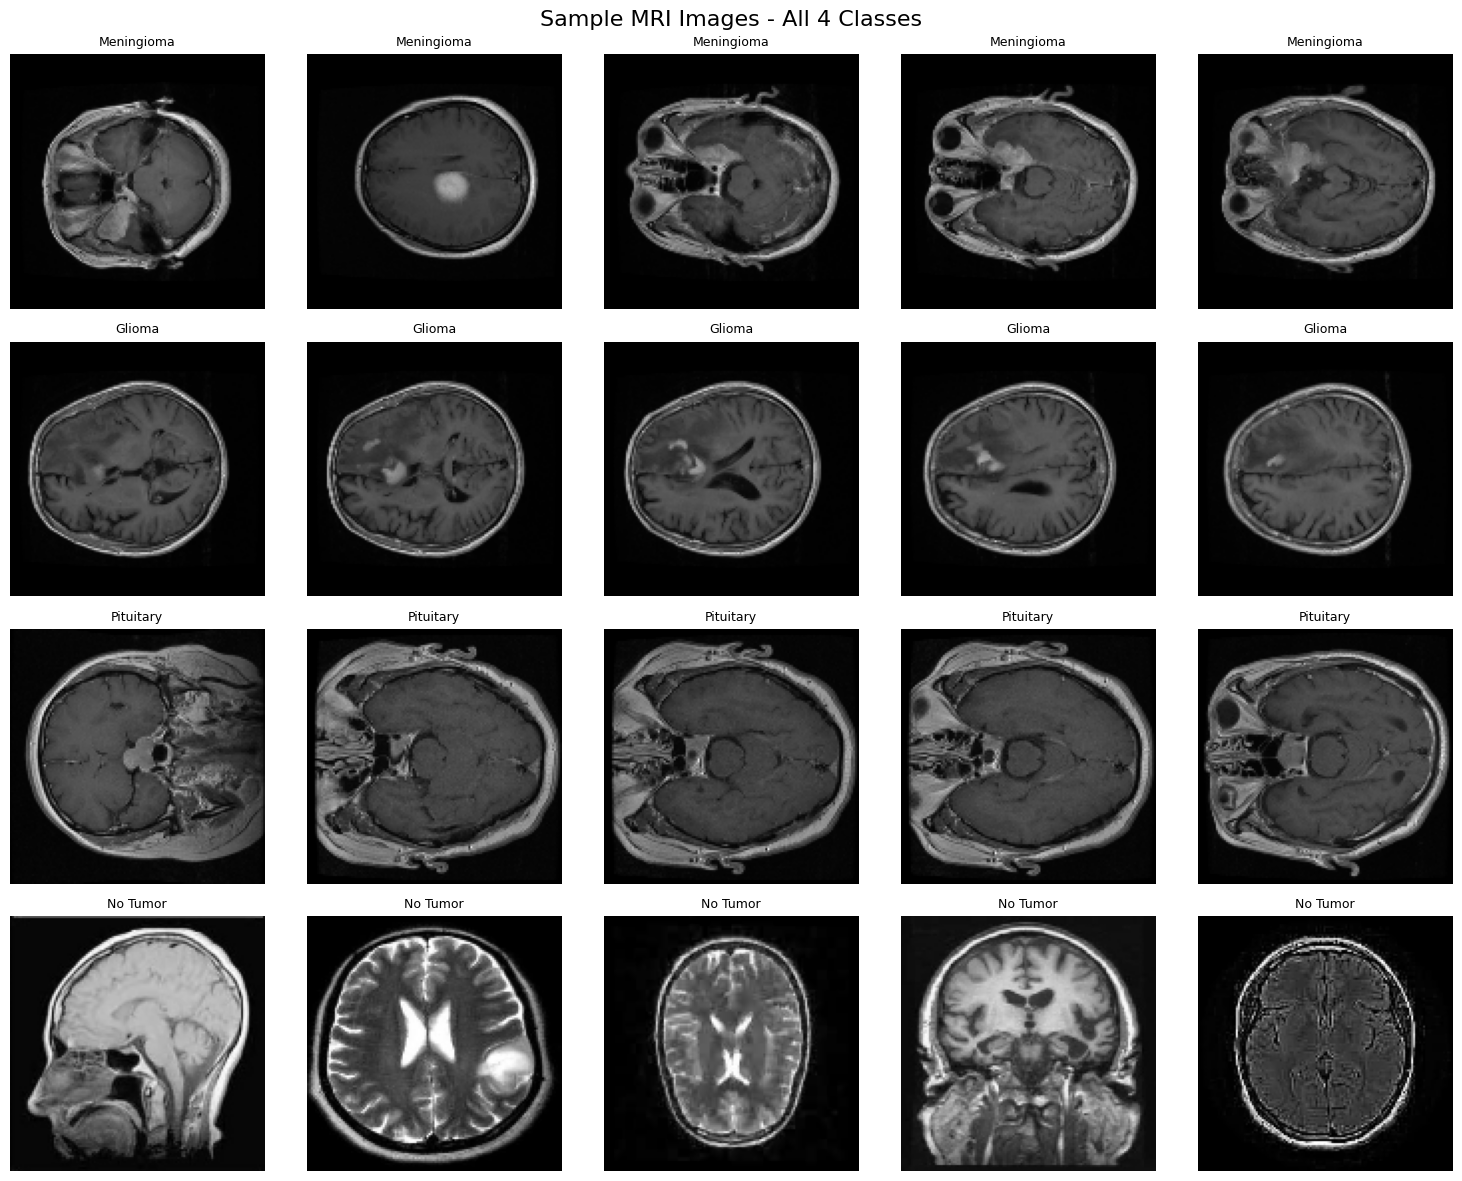

In [ ]:
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
fig.suptitle('Sample MRI Images - All 4 Classes', fontsize=16)

for row, cls in enumerate(range(4)):
    idxs = np.where(labels == cls)[0][:5]
    for col, idx in enumerate(idxs):
        axes[row, col].imshow(images[idx])
        axes[row, col].set_title(label_names[cls], fontsize=9)
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
X = images.astype(np.float32) / 255.0
y = labels
y_cat = to_categorical(y, num_classes=4)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_cat, test_size=0.30,
    random_state=42, stratify=y_cat)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    random_state=42, stratify=y_temp)

print("Split done!")
print(f"Training   : {X_train.shape}")
print(f"Validation : {X_val.shape}")
print(f"Testing    : {X_test.shape}")

Split done!
Training   : (7184, 128, 128, 3)
Validation : (1540, 128, 128, 3)
Testing    : (1540, 128, 128, 3)


In [ ]:
model = models.Sequential([
    # Block 1
    layers.Conv2D(32, (3,3), activation='relu',
                  padding='same', input_shape=(128, 128, 3)),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(2,2),
    layers.Dropout(0.25),

    # Block 2
    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(2,2),
    layers.Dropout(0.25),

    # Block 3
    layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(2,2),
    layers.Dropout(0.25),

    # Fully Connected
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.50),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.30),

    # Output
    layers.Dense(4, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,711,204 (33.23 MB)

 Trainable params: 8,710,244 (33.23 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1
)
datagen.fit(X_train)

early_stop = EarlyStopping(
    monitor='val_accuracy',
    patience=7,
    restore_best_weights=True)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6)

history = model.fit(
    datagen.flow(X_train, y_train, batch_size=32),
    epochs=30,
    validation_data=(X_val, y_val),
    callbacks=[early_stop, reduce_lr]
)

print("Training complete!")

Epoch 1/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 67s 217ms/step - accuracy: 0.6224 - loss: 0.9657 - val_accuracy: 0.2662 - val_loss: 3.3524 - learning_rate: 0.0010
Epoch 2/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 35s 156ms/step - accuracy: 0.7199 - loss: 0.7029 - val_accuracy: 0.3974 - val_loss: 3.8965 - learning_rate: 0.0010
Epoch 3/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 34s 152ms/step - accuracy: 0.7688 - loss: 0.5904 - val_accuracy: 0.6831 - val_loss: 0.9942 - learning_rate: 0.0010
Epoch 4/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 34s 150ms/step - accuracy: 0.8144 - loss: 0.5047 - val_accuracy: 0.3273 - val_loss: 2.7741 - learning_rate: 0.0010
Epoch 5/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 34s 152ms/step - accuracy: 0.8298 - loss: 0.4482 - val_accuracy: 0.7357 - val_loss: 0.9227 - learning_rate: 0.0010
Epoch 6/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 33s 148ms/step - accuracy: 0.8630 - loss: 0.3720 - val_accuracy: 0.7584 - val_loss: 0.7804 - learning_rate: 0.0010
Epoch 7/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 35s 155ms/step - accuracy: 0.8

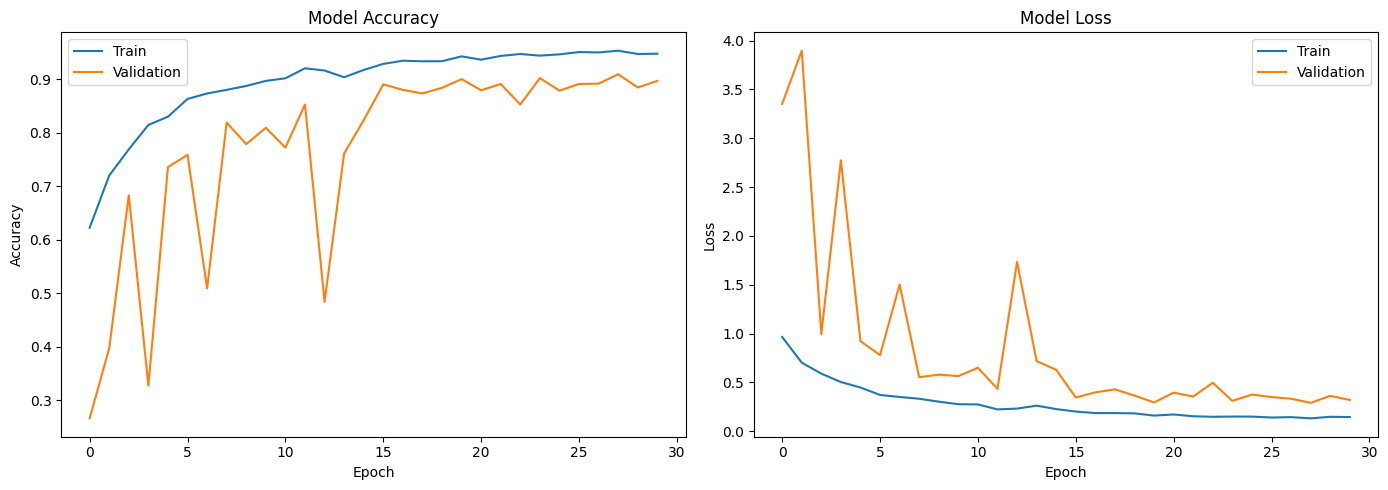

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Train')
axes[0].plot(history.history['val_accuracy'], label='Validation')
axes[0].set_title('Model Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(history.history['loss'], label='Train')
axes[1].plot(history.history['val_loss'], label='Validation')
axes[1].set_title('Model Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 51ms/step
Classification Report:
              precision    recall  f1-score   support

  Meningioma       0.99      0.76      0.86       377
      Glioma       0.96      0.94      0.95       484
   Pituitary       0.84      0.99      0.91       409
    No Tumor       0.92      0.99      0.95       270

    accuracy                           0.92      1540
   macro avg       0.93      0.92      0.92      1540
weighted avg       0.93      0.92      0.92      1540



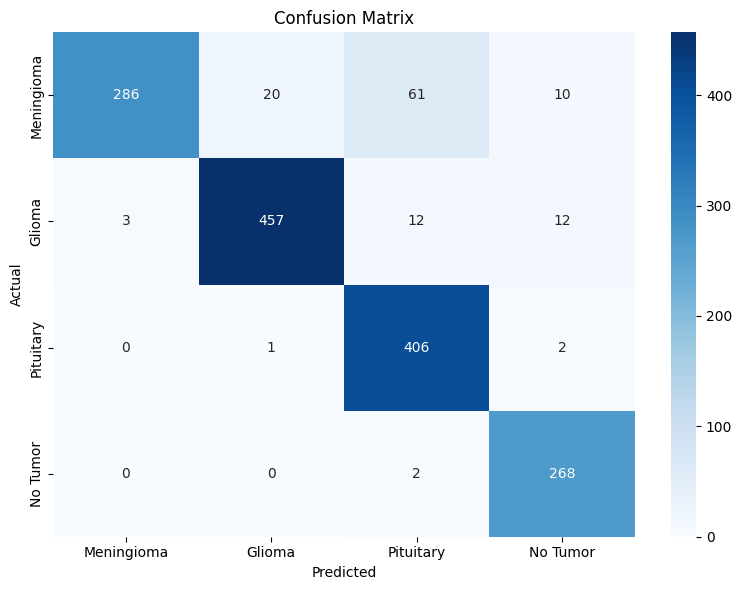

In [ ]:
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

class_names = ['Meningioma', 'Glioma', 'Pituitary', 'No Tumor']

print("Classification Report:")
print(classification_report(
    y_true_classes, y_pred_classes,
    target_names=class_names))

cm = confusion_matrix(y_true_classes, y_pred_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

In [ ]:
# Save to Drive so it never gets deleted
model.save("/content/drive/MyDrive/BrainTumor/brain_tumor_cnn.h5")
print("Model saved to Google Drive!")

# Also download to laptop
from google.colab import files
files.download("/content/drive/MyDrive/BrainTumor/brain_tumor_cnn.h5")
print("Model downloaded!")

Model saved to Google Drive!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model downloaded!
